[![Open in Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/africlimate-research/ACMAD_Seasonal_Calibration/blob/main/ACMAD_OND_IDR_Offline_Practical.ipynb)

To run this practical in Colab, click the badge and run **Section 0 — Setup** first. It clones the repository and installs the required packages.

# ACMAD Summer School | Seasonal rainfall calibration with IDR
**Practical (60 minutes) · Offline · September-initialized OND rainfall · SEAS5 and CHIRPS**

**Learning goal:** turn SEAS5 seasonal rainfall predictions into probabilistic forecasts using **isotonic distributional regression (IDR)**, and verify whether calibration provides useful skill relative to climatology. The calibration is to **Chirps**.

**Important:** Historical `seas5_OND.npy` is a single value per year/location (the SEAS5 predictor), **not the individual ensemble members**. We evaluate calibrated forecasts against the historical observational climatology; we cannot calculate raw-ensemble CRPS from these files.

### Timing
| Time | Activity |
|---|---|
| 0–10 min | Inspect data, bias, and WMO climatology |
| 10–25 min | Fit IDR and plot predictive distributions |
| 25–40 min | Turn distributions into tercile probabilities |
| 40–55 min | Brier score, Brier skill score, and reliability |
| 55–60 min | Operational interpretation and the 2026 extension |

## 0 — Setup (run first)



In [26]:
import os, sys
from pathlib import Path

REPO = "https://github.com/africlimate-research/ACMAD_Seasonal_Calibration.git"   # edit
project_path = Path("/content/acmad-idr-practical")

if not project_path.exists():
    !git clone -q {REPO} {project_path}

os.chdir(project_path)
sys.path.insert(0, str(project_path))
!pip install -q -r data/requirements.txt
print("Files in data folder:", os.listdir("data"))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 36.7 MB/s eta 0:00:00
Files in data folder: ['zone_mean_wmo_OND.npy', 'y_mean_wmo_OND.npy', 'chirps_obs_OND.npy', 'zone_std_wmo_OND.npy', 'y_std_wmo_OND.npy', 'seas5_OND.npy', 'pred_years_OND.npy', 'requirements.txt']


## 1 — Understand the prepared data (10 min)

Each row is an OND year and each column is one spatial location, with corresponding locations across files. We do **not** know each column's latitude/longitude from the supplied arrays, so **do not reshape the 12,424 values into a map**. The supplied geographic extent describes a bounding box but does not define the selected-point ordering.

The `y_mean_wmo_OND` and `y_std_wmo_OND` arrays provide location-specific reference statistics. The `zone_*` arrays contain zone-based references; they are **not zone labels**, so we cannot recreate zone-pooled IDR without extra metadata.

In [29]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from idr_xarray import IDRModel

DATA = Path('data')
X = np.load(DATA/'seas5_OND.npy')  # SEAS5 historical OND predictor
Y = np.load(DATA/'chirps_obs_OND.npy')  # CHIRPS observed OND total
YEARS = np.load(DATA/'pred_years_OND.npy')
WMO_MEAN = np.load(DATA/'y_mean_wmo_OND.npy')
WMO_STD = np.load(DATA/'y_std_wmo_OND.npy')
ZONE_MEAN = np.load(DATA/'zone_mean_wmo_OND.npy')
ZONE_STD = np.load(DATA/'zone_std_wmo_OND.npy')
assert X.shape == Y.shape == (len(YEARS), len(WMO_MEAN))
assert np.array_equal(YEARS, np.arange(2001, 2026))
assert np.isfinite(X).all() and np.isfinite(Y).all()
print(f'{X.shape[0]} OND seasons ({YEARS[0]}–{YEARS[-1]}); {X.shape[1]:,} aligned locations')
print(f'SEAS5 mean: {X.mean():.1f} mm | CHIRPS mean: {Y.mean():.1f} mm')
print(f'WMO reference location means: {WMO_MEAN.min():.1f}–{WMO_MEAN.max():.1f} mm')

25 OND seasons (2001–2025); 12,424 aligned locations
SEAS5 mean: 156.8 mm | CHIRPS mean: 142.3 mm
WMO reference location means: 0.0–1094.1 mm


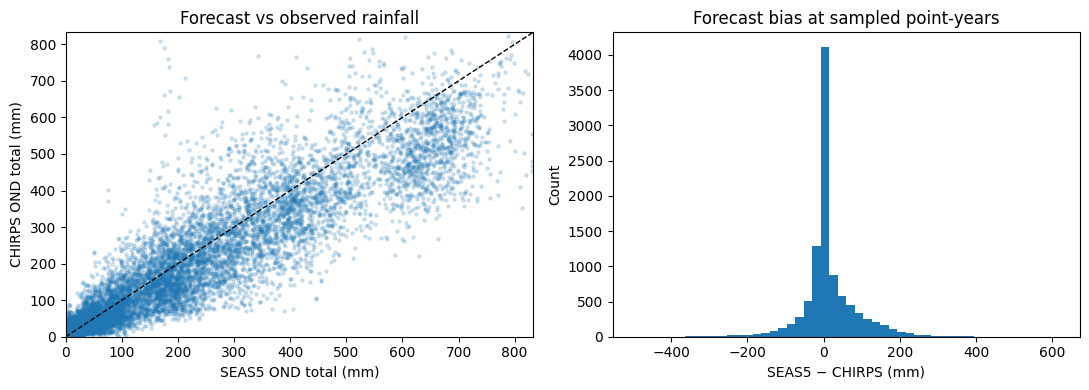

In [28]:
rng = np.random.default_rng(2026)
point_ids = rng.choice(X.shape[1], size=600, replace=False)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(X[:,point_ids].ravel(), Y[:,point_ids].ravel(), s=5, alpha=.18)
lim = float(max(np.quantile(X, .995),np.quantile(Y,.995)))
ax[0].plot([0,lim],[0,lim],'k--',lw=1)
ax[0].set(xlim=(0,lim), ylim=(0,lim),xlabel='SEAS5 OND total (mm)',ylabel='CHIRPS OND total (mm)',title='Forecast vs observed rainfall')
ax[1].hist((X-Y).ravel()[rng.choice(X.size, 10000, replace=False)],bins=50)
ax[1].set(xlabel='SEAS5 − CHIRPS (mm)',ylabel='Count',title='Forecast bias at sampled point-years')
plt.tight_layout(); plt.show()

**Discuss:** Does bias vary by rainfall amount? Would subtracting the average bias capture forecast uncertainty? Why might a whole predictive distribution be more useful than one corrected rainfall value?

## 2 — Fit isotonic distributional regression (15 min)

IDR estimates the conditional cumulative distribution function **\(F(t \mid x)=P(Y\leq t\mid X=x)\)**. It imposes a monotonic ordering: wetter SEAS5 predictions should correspond to distributions shifted toward wetter observations. Unlike simple linear regression, IDR provides *probabilities at every threshold*.

**No validation leakage:** fit on 2001–2015 and evaluate on unseen **2016–2025**. This is a teaching split, **not** the full leave-one-year-out evaluation from the research pipeline.

For fast classroom execution, sample up to 1,200 historical point-year pairs for training and 1,500 for validation. The IDR fit uses **pooled point-years**, rather than separate Köppen–Geiger zone models. Spatial correlation means these pairs are not independent; interpret scores as a teaching demonstration, not a published Africa-wide skill estimate.

In [18]:
is_train = YEARS <= 2015
is_test = YEARS >= 2016
x_train_all, y_train_all = X[is_train].ravel(), Y[is_train].ravel()
x_test_all, y_test_all = X[is_test].ravel(), Y[is_test].ravel()
seed = np.random.default_rng(42)
i_train = seed.choice(len(x_train_all), size=min(1200,len(x_train_all)), replace=False)
i_test = seed.choice(len(x_test_all), size=min(1500,len(x_test_all)), replace=False)
xtrain, ytrain = x_train_all[i_train], y_train_all[i_train]
xtest, ytest = x_test_all[i_test], y_test_all[i_test]
idr = IDRModel().fit(xtrain, ytrain)
print(f'Fitted IDR on {len(xtrain):,} pairs; testing on {len(xtest):,} unseen-year pairs')

Fitted IDR on 1,200 pairs; testing on 1,500 unseen-year pairs


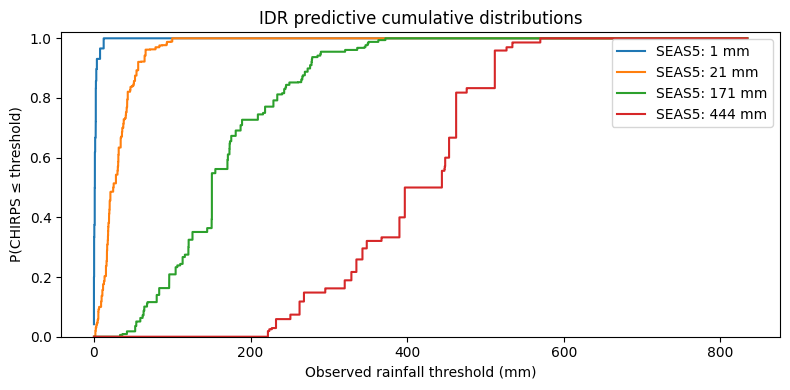

In [ ]:
example_x = np.quantile(xtrain,[.1,.4,.7,.9])
dist = idr.predict(example_x)
fig,ax=plt.subplots(figsize=(8,4))
for i, xx in enumerate(example_x):
    ax.step(dist.thresholds,dist.cdf[i],where='post',label=f'SEAS5: {xx:.0f} mm')
ax.set(xlabel='Observed rainfall threshold (mm)',ylabel='P(CHIRPS ≤ threshold)',title='IDR predictive cumulative distributions',ylim=(0,1.02))
ax.legend();plt.tight_layout();plt.show()

**Discuss:** At a fixed rainfall threshold, which forecast has the highest probability of a dry outcome? What shape or monotonicity restrictions do you see?

## 3 — Derive tercile probabilities (15 min)

For this simple pooled model, calculate **pooled** 1/3 and 2/3 CHIRPS thresholds using **training years only**. Then compute:

\[P(BN)=F(q_{1/3}\mid x),\quad P(NN)=F(q_{2/3}\mid x)-F(q_{1/3}\mid x),\quad P(AN)=1-F(q_{2/3}\mid x).\]

**Operational caveat:** Official seasonal terciles are typically **location-specific** and based on a fixed reference (often 1991–2020). These globally pooled cutoffs are intentionally simplified. The supplied WMO **means and standard deviations do not uniquely determine empirical tercile cutoffs**; do not treat mean ± standard deviation as observed terciles. When original grid metadata and reference-year observations are available, calculate pixel-specific thresholds.

In [20]:
q1,q2 = np.quantile(y_train_all,[1/3,2/3])
pred = idr.predict(xtest)
p_bn = np.atleast_1d(pred.cdf_at(q1))
p_not_an = np.atleast_1d(pred.cdf_at(q2))
P = np.column_stack([p_bn, p_not_an-p_bn, 1-p_not_an])
assert np.all(P >= -1e-8) and np.allclose(P.sum(axis=1),1,atol=1e-7)
obs_cat = np.digitize(ytest,[q1,q2],right=True)
print(f'Pooled tercile thresholds: BN ≤ {q1:.1f} mm; AN > {q2:.1f} mm')
for j,label in enumerate(['BN','NN','AN']):
    print(f'{label}: average forecast probability {P[:,j].mean():.3f}; observed frequency {(obs_cat==j).mean():.3f}')

Pooled tercile thresholds: BN ≤ 15.8 mm; AN > 146.9 mm
BN: average forecast probability 0.339; observed frequency 0.319
NN: average forecast probability 0.319; observed frequency 0.345
AN: average forecast probability 0.342; observed frequency 0.336


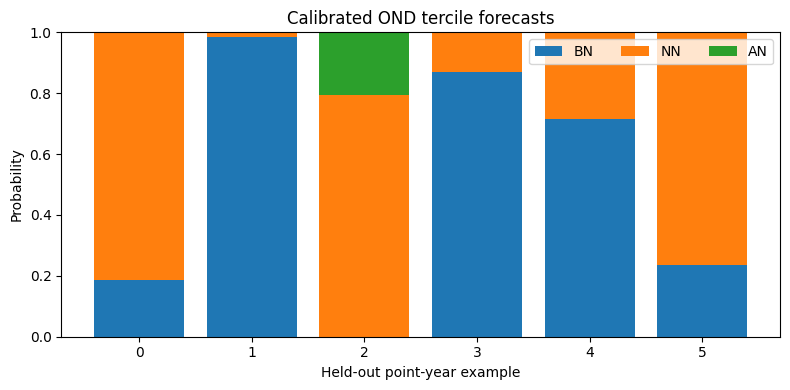

In [21]:
sample = np.arange(6)
fig,ax=plt.subplots(figsize=(8,4))
bottom=np.zeros(len(sample))
for j,lab in enumerate(['BN','NN','AN']):
    ax.bar(sample,P[sample,j],bottom=bottom,label=lab)
    bottom += P[sample,j]
ax.set(ylim=(0,1),xlabel='Held-out point-year example',ylabel='Probability',title='Calibrated OND tercile forecasts')
ax.legend(ncol=3);plt.tight_layout();plt.show()

## 4 — Verify forecast skill, discrimination and reliability (15 min)

The **Brier score** is \(BS=\mathrm{mean}(p-o)^2\) for a binary category event. Lower is better. **Brier skill score** against a training-derived climatology is \(BSS=1-BS_{IDR}/BS_{clim}\); positive BSS means improvement.

Reference probabilities below are determined **only from the training years**. This tests calibration versus a fair pooled-frequency baseline; it is not the full spatially varying operational climatology. No raw-ensemble probabilities are available in the supplied input.

**ROC AUC** measures discrimination: how well forecast probabilities rank event years above non-event years, over all probability thresholds. AUC = 0.5 corresponds to chance ranking; AUC = 1 is perfect ranking. Unlike Brier score, AUC does **not** assess probability calibration. We calculate one-versus-rest ROC curves for each rainfall tercile on the same held-out 2016–2025 samples.


In [22]:
names=['Below normal','Near normal','Above normal']
train_cat=np.digitize(y_train_all,[q1,q2],right=True)
p_clim=np.array([(train_cat==j).mean() for j in range(3)])
results=[]
for j,name in enumerate(names):
    outcome=(obs_cat==j).astype(float)
    bs=np.mean((P[:,j]-outcome)**2)
    bs_ref=np.mean((p_clim[j]-outcome)**2)
    results.append((name,bs,bs_ref,1-bs/bs_ref))
print(f'{"Category":<15} {"IDR BS":>9} {"Clim BS":>10} {"BSS":>9}')
for name,bs,br,bss in results:
    print(f'{name:<15} {bs:9.4f} {br:10.4f} {bss:9.3f}')

Category           IDR BS    Clim BS       BSS
Below normal       0.0601     0.2173     0.723
Near normal        0.1094     0.2262     0.517
Above normal       0.0505     0.2231     0.774


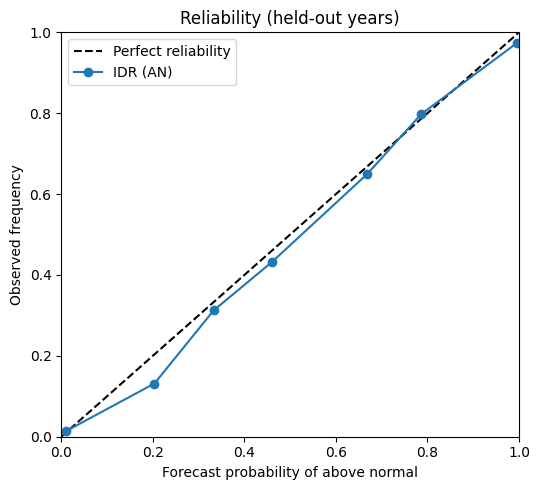

Bin sample counts: [np.int64(878), np.int64(38), np.int64(16), np.int64(44), np.int64(100), np.int64(84), np.int64(340)]


In [ ]:
p=P[:,2]; o=(obs_cat==2).astype(float)
edges=np.linspace(0,1,9)
mean_p=[]; freq=[]; counts=[]
for lo,hi in zip(edges[:-1],edges[1:]):
    mask=(p>=lo)&((p<hi) if hi<1 else (p<=hi))
    if mask.sum()>=10:
        mean_p.append(p[mask].mean());freq.append(o[mask].mean());counts.append(mask.sum())
fig,ax=plt.subplots(figsize=(5.5,5))
ax.plot([0,1],[0,1],'k--',label='Perfect reliability')
ax.plot(mean_p,freq,'o-',label='IDR (AN)')
ax.set(xlim=(0,1),ylim=(0,1),xlabel='Forecast probability of above normal',ylabel='Observed frequency',title='Reliability (held-out years)')
ax.legend();plt.tight_layout();plt.show()
print('Bin sample counts:',counts)

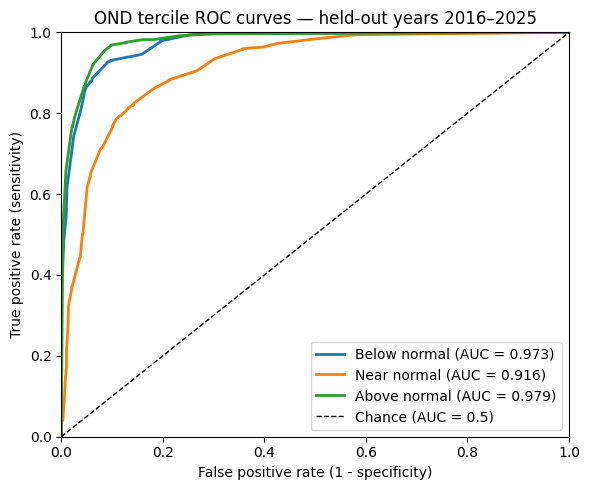

Category           ROC AUC     Events    Cases
Below normal         0.973        478     1500
Near normal          0.916        518     1500
Above normal         0.979        504     1500


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

fig, ax = plt.subplots(figsize=(6, 5))
roc_results = []
for j, name in enumerate(names):
    observed = (obs_cat == j).astype(int)
    forecast_prob = P[:, j]
    if np.unique(observed).size < 2:
        print(f'{name}: ROC AUC undefined (test subset has only one outcome class)')
        continue
    fpr, tpr, probability_cutoffs = roc_curve(observed, forecast_prob)
    auc = roc_auc_score(observed, forecast_prob)
    roc_results.append((name, auc, int(observed.sum()), len(observed)))
    ax.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {auc:.3f})')

ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Chance (AUC = 0.5)')
ax.set(xlim=(0, 1), ylim=(0, 1),
       xlabel='False positive rate (1 - specificity)',
       ylabel='True positive rate (sensitivity)',
       title='OND tercile ROC curves — held-out years 2016–2025')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

print(f'{"Category":<17} {"ROC AUC":>8} {"Events":>10} {"Cases":>8}')
for name, auc, n_events, n_cases in roc_results:
    print(f'{name:<17} {auc:8.3f} {n_events:10d} {n_cases:8d}')


**Interpretation exercise:** Compare the three ROC AUC values with their Brier Skill Scores. Which category best separates event and non-event cases? Can high ROC AUC coexist with poor reliability? Why should scores pooled across thousands of locations **not** be interpreted as thousands of independent forecast years? (The 10 held-out seasons share large-scale weather conditions.)

**Discuss:** Which tercile has positive BSS and the highest ROC AUC? Are some probability bins poorly sampled? How could pooling across dissimilar rain regimes produce misleading regional skill?

## 5 — Optional: September 2026 SEAS5 NetCDF (5-minute preview)

The historical IDR tutorial above **works without** the 2026 forecast. When the large September 2026 NetCDF file becomes available, **keep it on your computer** (it does not need to be uploaded or copied into this tutorial folder). Point the following cell at its location. The inspection uses lazy xarray loading and does not read the entire file into memory.

**Important:** We cannot automatically calibrate or map this forecast yet because the archived historical arrays contain 12,424 selected points but do **not** include their geographic indices or original predictor-preprocessing recipe. We must verify these before claiming a 2026 probability forecast. The `africa_standard_extent.json` is a bounding box, not a cell-to-column mapping.


In [ ]:
# OPTIONAL — skip this cell until the September 2026 NetCDF is on your computer.
import os
from pathlib import Path

# On Google Colab, put the file in Google Drive and mount it first:
#     from google.colab import drive; drive.mount("/content/drive")
# then use e.g. Path("/content/drive/MyDrive/seas5_september_2026.nc").
# On a shared JupyterHub, set this to the shared data path given by the facilitator,
# e.g. Path("/home/shared/acmad/seas5_september_2026.nc"), or set env var SEAS5_2026_NC.
FORECAST_NC = Path(os.environ.get("SEAS5_2026_NC", Path.home() / "path/to/seas5_september_2026.nc"))  # EDIT THIS PATH

if not FORECAST_NC.is_file():
    print(f"No local NetCDF found at {FORECAST_NC}. Skipping 2026 extension.")
else:
    import xarray as xr
    with xr.open_dataset(FORECAST_NC, chunks={}) as ds_2026:
        print('Dimensions:', dict(ds_2026.sizes))
        print('Variables:', list(ds_2026.data_vars))
        print('Coordinates:', list(ds_2026.coords))
        for name, da in ds_2026.data_vars.items():
            print(f"  {name}: dims={da.dims}, units={da.attrs.get('units', 'unspecified')}, "
                  f"long_name={da.attrs.get('long_name', 'unspecified')}")
        print('Time/lead sample:')
        for name in ds_2026.coords:
            if 'time' in name.lower() or 'period' in name.lower() or 'step' in name.lower():
                print(f"  {name}: {ds_2026[name].isel({ds_2026[name].dims[0]: slice(0, 3)}).values}")


### What we will add once the NetCDF structure is confirmed

1. Identify `total_precipitation`, its accumulation units (e.g. metres of accumulated water), lead-time coordinate and ensemble dimensions. **Do not sum cumulative precipitation directly**: first compute stepwise increments from cumulative amounts if applicable.
2. Aggregate the **September-initialized OND** period using the same date coverage as the historical processing (the previous 120-day convention can omit **31 December**; this must be checked).
3. Transform the forecast onto the same grid and **the same 12,424 locations in the same order** as `seas5_OND.npy`. We cannot infer these positions from the number of locations or the bounding box alone.
4. Once alignment is verified, refit IDR on the full historical dataset and obtain conditional rainfall probabilities for 2026. The current notebook uses **pooled tercile thresholds** for instruction, not locally defined WMO terciles. An operational product would need local thresholds and further validation.
5. Only after recovering the geographic index should we draw OND 2026 maps.

**No GCS authentication is necessary** for this extension: the file is read from a local path. For very large files, install `dask` and `netcdf4` (or an appropriate NetCDF engine); xarray opens the dataset lazily, and we should select only the relevant variable, period and region before computing data.

### Take-home questions
- What does it mean for a probabilistic forecast to be *reliable* but have little *skill*?
- Why must climatology reference values be estimated without test-year observations?
- Does calibration create predictability where none existed?
